In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, cross_val_predict
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import classification_report, confusion_matrix
from xgboost import XGBClassifier

In [2]:
paths = [
    Path("data/raw/student_mental_health.csv"),
    Path("../data/raw/student_mental_health.csv"),
    Path("student_mental_health.csv")
]

csv_path = next((p for p in paths if p.exists()), None)
if csv_path is None:
    raise FileNotFoundError("Place student_mental_health.csv in data/raw/")

df = pd.read_csv(csv_path)
print("Dimensions:", df.shape)
display(df.head(3))

Dimensions: (2000, 17)


,Student_ID,Age,Gender,Year_of_Study,Sleep_Hours,Study_Hours_Per_Week,GPA,Social_Media_Hours,Screen_Time_Hours,Physical_Activity,Financial_Stress,Family_Support,Attendance_Rate,Part_Time_Job,Diet_Quality,Previous_Mental_Health_History,Mental_Health_Risk
0,STU0001,22,Male,3,6.6,17.6,2.91,6.9,7.5,Moderate,8.5,4.0,78.0,No,Poor,No,High
1,STU0002,21,Male,4,5.6,22.4,2.92,7.6,11.5,Low,4.5,5.3,85.4,Yes,Average,No,Medium
2,STU0003,22,Male,5,7.1,28.1,2.68,6.5,8.9,Low,4.8,6.1,79.5,No,Average,No,Medium


In [3]:
target = "Mental_Health_Risk"
df = df.dropna(subset=[target]).copy()

X = df.drop(columns=["Student_ID", target])
y = df[target]

print("Number of input features:", X.shape[1])
print("Classes:", sorted(y.unique()))
print("Students per class:")
print(y.value_counts())

Number of input features: 15
Classes: ['High', 'Low', 'Medium']
Students per class:
Mental_Health_Risk
High      680
Medium    660
Low       660
Name: count, dtype: int64


In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

class_mapping = {"Low": 0, "Medium": 1, "High": 2}
y_train = y_train.map(class_mapping)
y_test = y_test.map(class_mapping)

print("Train:", X_train.shape)
print("Test:", X_test.shape)
print("Training class distribution:")
print(y_train.value_counts().sort_index())

Train: (1600, 15)
Test: (400, 15)
Training class distribution:
Mental_Health_Risk
0    528
1    528
2    544
Name: count, dtype: int64


In [5]:
numeric_columns = X_train.select_dtypes(include="number").columns.tolist()
categorical_columns = X_train.select_dtypes(exclude="number").columns.tolist()

print("Numerical columns:", numeric_columns)
print("Categorical columns:", categorical_columns)

Numerical columns: ['Age', 'Year_of_Study', 'Sleep_Hours', 'Study_Hours_Per_Week', 'GPA', 'Social_Media_Hours', 'Screen_Time_Hours', 'Financial_Stress', 'Family_Support', 'Attendance_Rate']
Categorical columns: ['Gender', 'Physical_Activity', 'Part_Time_Job', 'Diet_Quality', 'Previous_Mental_Health_History']


In [6]:
class IQRClipper(BaseEstimator, TransformerMixin):
    def fit(self, X, y=None):
        X = pd.DataFrame(X)
        q1 = X.quantile(0.25)
        q3 = X.quantile(0.75)
        iqr = q3 - q1
        self.lower_bounds_ = q1 - 1.5 * iqr
        self.upper_bounds_ = q3 + 1.5 * iqr
        return self

    def transform(self, X):
        X = pd.DataFrame(X)
        return X.clip(self.lower_bounds_, self.upper_bounds_, axis=1).to_numpy()

In [7]:
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("iqr", IQRClipper()),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
])

preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, numeric_columns),
    ("cat", categorical_pipeline, categorical_columns)
])

print("Preprocessing ready: imputation + IQR + encoding + scaling")

Preprocessing ready: imputation + IQR + encoding + scaling


In [8]:
models = {
    "Random Forest": RandomForestClassifier(
        n_estimators=100, random_state=42, n_jobs=2
    ),
    "XGBoost": XGBClassifier(
        n_estimators=100, max_depth=3, learning_rate=0.1,
        objective="multi:softprob", eval_metric="mlogloss",
        random_state=42, n_jobs=2
    ),
    "SVM": SVC(kernel="rbf", C=1.0)
}

print("Models to compare:", list(models))

Models to compare: ['Random Forest', 'XGBoost', 'SVM']


In [9]:
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)

metrics = {
    "accuracy": "accuracy",
    "precision": "precision_macro",
    "recall": "recall_macro",
    "f1": "f1_macro"
}

results = []
trained_pipelines = {}

for name, model in models.items():
    pipeline = Pipeline([
        ("preprocessing", clone(preprocessor)),
        ("model", clone(model))
    ])

    scores = cross_validate(
        pipeline, X_train, y_train,
        cv=cv, scoring=metrics, n_jobs=1
    )

    pipeline.fit(X_train, y_train)
    trained_pipelines[name] = pipeline

    results.append({
        "Model": name,
        "Accuracy": scores["test_accuracy"].mean(),
        "Precision_macro": scores["test_precision"].mean(),
        "Recall_macro": scores["test_recall"].mean(),
        "F1_macro": scores["test_f1"].mean()
    })

comparison = pd.DataFrame(results).sort_values("F1_macro", ascending=False)
display(comparison.round(3))

,Model,Accuracy,Precision_macro,Recall_macro,F1_macro
2,SVM,0.716,0.718,0.716,0.717
1,XGBoost,0.682,0.676,0.681,0.677
0,Random Forest,0.673,0.662,0.672,0.664


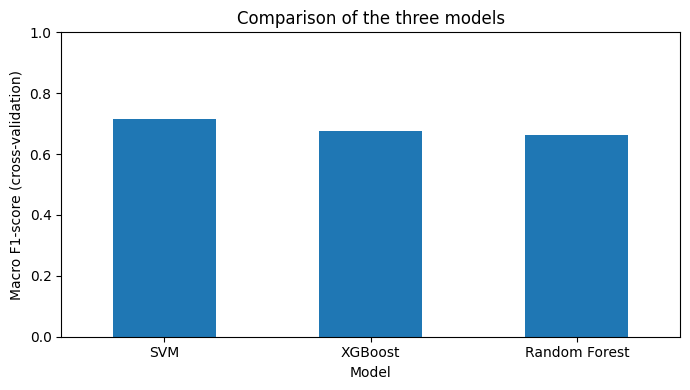

In [10]:
comparison.plot(x="Model", y="F1_macro", kind="bar", legend=False, figsize=(7, 4))
plt.ylabel("Macro F1-score (cross-validation)")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.title("Comparison of the three models")
plt.tight_layout()
plt.show()

In [11]:
best_model_name = comparison.iloc[0]["Model"]
print("Best model before tuning:", best_model_name)

pipeline_cv = Pipeline([
    ("preprocessing", clone(preprocessor)),
    ("model", clone(models[best_model_name]))
])

predictions_cv = cross_val_predict(
    pipeline_cv, X_train, y_train, cv=cv, n_jobs=1
)

print(classification_report(
    y_train, predictions_cv,
    labels=[0, 1, 2],
    target_names=["Low", "Medium", "High"],
    zero_division=0
))

Best model before tuning: SVM
              precision    recall  f1-score   support

         Low       0.79      0.80      0.79       528
      Medium       0.58      0.60      0.59       528
        High       0.79      0.75      0.77       544

    accuracy                           0.72      1600
   macro avg       0.72      0.72      0.72      1600
weighted avg       0.72      0.72      0.72      1600



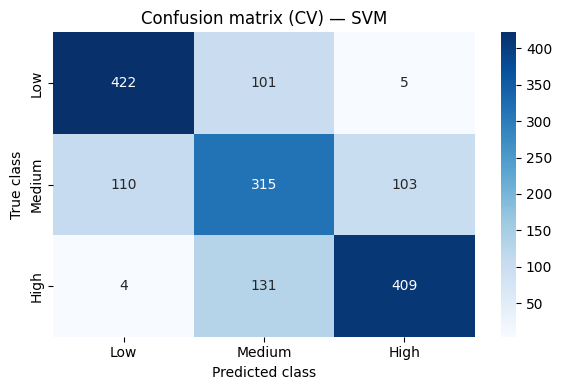

In [12]:
matrix = confusion_matrix(y_train, predictions_cv, labels=[0, 1, 2])

plt.figure(figsize=(6, 4))
sns.heatmap(
    matrix, annot=True, fmt="d", cmap="Blues",
    xticklabels=["Low", "Medium", "High"],
    yticklabels=["Low", "Medium", "High"]
)
plt.xlabel("Predicted class")
plt.ylabel("True class")
plt.title(f"Confusion matrix (CV) — {best_model_name}")
plt.tight_layout()
plt.show()